# 04 — Temporal Churn Prediction

Predict whether a customer will fail to purchase during the next 90 days.

The key design decision is temporal validation:

**past behavior → future purchase outcome**

This avoids using future information as model features.


In [3]:
# ============================================================
# 04 — TEMPORAL CHURN PREDICTION
# CELL 1 — IMPORTS + DATA LOADING
# ============================================================

from pathlib import Path
import sys

# ============================================================
# PROJECT ROOT
# ============================================================

# Notebook is inside:
# Customer Intelligence Platform/notebooks/

ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

# Add project root to Python path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


# ============================================================
# STANDARD LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# SCIKIT-LEARN
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
    ConfusionMatrixDisplay
)


# ============================================================
# XGBOOST
# ============================================================

from xgboost import XGBClassifier


# ============================================================
# PROJECT MODULES
# ============================================================

# IMPORTANT:
# Your churn_model.py contains:
#
# create_temporal_train_test()
# CHURN_FEATURES
#
# It does NOT contain:
#
# temporal_train_test
# FEATURES

from ml.churn_model import (
    create_temporal_train_test,
    CHURN_FEATURES
)

from ml.evaluation import (
    classification_metrics
)


# ============================================================
# DATA PATH
# ============================================================

TX = (
    ROOT
    / "data"
    / "processed"
    / "transactions.csv"
)


# ============================================================
# CHECK DATASET EXISTS
# ============================================================

if not TX.exists():

    raise FileNotFoundError(
        "\ntransactions.csv was not found.\n\n"
        f"Expected location:\n{TX}\n\n"
        "Please run the preprocessing step first."
    )


# ============================================================
# LOAD DATASET
# ============================================================

df = pd.read_csv(
    TX,
    parse_dates=["InvoiceDate"]
)


# ============================================================
# BASIC DATA VALIDATION
# ============================================================

if "InvoiceDate" not in df.columns:

    raise ValueError(
        "InvoiceDate column is missing from transactions.csv"
    )


if "CustomerID" not in df.columns:

    raise ValueError(
        "CustomerID column is missing from transactions.csv"
    )


# ============================================================
# SORT DATA
# ============================================================

df = (
    df
    .sort_values("InvoiceDate")
    .reset_index(drop=True)
)


# ============================================================
# DISPLAY INFORMATION
# ============================================================

print("=" * 70)
print("STEP 4 — TEMPORAL CHURN PREDICTION")
print("=" * 70)

print("\nDataset shape:")
print(df.shape)

print("\nNumber of customers:")
print(
    df["CustomerID"]
    .nunique()
)

print("\nDate range:")

print(
    "Start:",
    df["InvoiceDate"].min()
)

print(
    "End  :",
    df["InvoiceDate"].max()
)


# ============================================================
# CHURN FEATURES
# ============================================================

print("\nChurn features:")

for feature in CHURN_FEATURES:
    print("  ✓", feature)


# ============================================================
# VERIFY FEATURES EXIST
# ============================================================

missing_features = [
    feature
    for feature in CHURN_FEATURES
    if feature not in df.columns
]

if missing_features:

    print("\nNOTE:")
    print(
        "The following churn features are not directly present "
        "in transactions.csv:"
    )

    for feature in missing_features:
        print("  -", feature)

    print(
        "\nThis is expected if these features are generated by "
        "create_customer_features()."
    )


print("\n" + "=" * 70)
print("DATA LOADED SUCCESSFULLY")
print("=" * 70)

STEP 4 — TEMPORAL CHURN PREDICTION

Dataset shape:
(793609, 10)

Number of customers:
5878

Date range:
Start: 2009-12-01 07:45:00
End  : 2011-12-09 12:50:00

Churn features:
  ✓ recency
  ✓ frequency
  ✓ monetary
  ✓ average_order_value
  ✓ customer_lifetime
  ✓ total_quantity
  ✓ unique_products
  ✓ avg_purchase_interval
  ✓ median_purchase_interval
  ✓ weekend_purchase_ratio
  ✓ avg_monthly_orders

NOTE:
The following churn features are not directly present in transactions.csv:
  - recency
  - frequency
  - monetary
  - average_order_value
  - customer_lifetime
  - total_quantity
  - unique_products
  - avg_purchase_interval
  - median_purchase_interval
  - weekend_purchase_ratio
  - avg_monthly_orders

This is expected if these features are generated by create_customer_features().

DATA LOADED SUCCESSFULLY


## Create temporal train/test snapshots

In [6]:
# ============================================================
# CREATE TEMPORAL TRAIN / TEST SNAPSHOTS
# ============================================================

print("=" * 70)
print("CREATING TEMPORAL TRAIN / TEST SNAPSHOTS")
print("=" * 70)

# ------------------------------------------------------------
# Determine the latest transaction date
# ------------------------------------------------------------

max_date = df["InvoiceDate"].max()

print(f"\nDataset maximum date: {max_date}")


# ------------------------------------------------------------
# Training observation cutoff
# ------------------------------------------------------------
# We leave 180 days at the end of the dataset so that
# the model has enough future data for the churn label.

cutoff = (
    max_date
    - pd.Timedelta(days=180)
)

print(f"Training cutoff:      {cutoff}")


# ------------------------------------------------------------
# Create temporal snapshots
# ------------------------------------------------------------

train, test = create_temporal_train_test(
    df=df,
    initial_cutoff=cutoff,
    prediction_days=90
)


# ------------------------------------------------------------
# Display shapes
# ------------------------------------------------------------

print("\n" + "-" * 70)

print(
    f"Training snapshot: {train.shape}"
)

print(
    f"Testing snapshot : {test.shape}"
)


# ------------------------------------------------------------
# Check that churn target exists
# ------------------------------------------------------------

if "churn" not in train.columns:
    raise ValueError(
        "The 'churn' column was not created in the training snapshot."
    )

if "churn" not in test.columns:
    raise ValueError(
        "The 'churn' column was not created in the testing snapshot."
    )


# ------------------------------------------------------------
# Target distribution
# ------------------------------------------------------------

print("\nTraining churn distribution:")
print(
    train["churn"]
    .value_counts()
)

print("\nTraining churn percentage:")
print(
    train["churn"]
    .value_counts(normalize=True)
)


print("\nTesting churn distribution:")
print(
    test["churn"]
    .value_counts()
)

print("\nTesting churn percentage:")
print(
    test["churn"]
    .value_counts(normalize=True)
)


# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if len(train) == 0:
    raise ValueError(
        "Training snapshot is empty. "
        "Please check the cutoff date and transaction data."
    )

if len(test) == 0:
    raise ValueError(
        "Testing snapshot is empty. "
        "Please check the temporal cutoff and prediction window."
    )


print("\n" + "=" * 70)
print("TEMPORAL TRAIN / TEST SNAPSHOTS CREATED SUCCESSFULLY")
print("=" * 70)

CREATING TEMPORAL TRAIN / TEST SNAPSHOTS

Dataset maximum date: 2011-12-09 12:50:00
Training cutoff:      2011-06-12 12:50:00

----------------------------------------------------------------------
Training snapshot: (4977, 22)
Testing snapshot : (304, 22)

Training churn distribution:
churn
1    3379
0    1598
Name: count, dtype: int64

Training churn percentage:
churn
1    0.678923
0    0.321077
Name: proportion, dtype: float64

Testing churn distribution:
churn
0    167
1    137
Name: count, dtype: int64

Testing churn percentage:
churn
0    0.549342
1    0.450658
Name: proportion, dtype: float64

TEMPORAL TRAIN / TEST SNAPSHOTS CREATED SUCCESSFULLY


In [8]:
# ============================================================
# CREATE FEATURE MATRICES
# ============================================================

print("=" * 70)
print("CREATING FEATURE MATRICES")
print("=" * 70)


# ------------------------------------------------------------
# Define the exact churn features
# ------------------------------------------------------------

CHURN_FEATURES = [

    "recency",

    "frequency",

    "monetary",

    "average_order_value",

    "customer_lifetime",

    "total_quantity",

    "unique_products",

    "avg_purchase_interval",

    "median_purchase_interval",

    "weekend_purchase_ratio",

    "avg_monthly_orders"
]


# ------------------------------------------------------------
# Check that all features exist in training data
# ------------------------------------------------------------

missing_train = [
    feature
    for feature in CHURN_FEATURES
    if feature not in train.columns
]

if missing_train:

    raise ValueError(
        "The following features are missing from the "
        "training dataset:\n\n"
        + "\n".join(
            f"  - {feature}"
            for feature in missing_train
        )
    )


# ------------------------------------------------------------
# Check that all features exist in test data
# ------------------------------------------------------------

missing_test = [
    feature
    for feature in CHURN_FEATURES
    if feature not in test.columns
]

if missing_test:

    raise ValueError(
        "The following features are missing from the "
        "test dataset:\n\n"
        + "\n".join(
            f"  - {feature}"
            for feature in missing_test
        )
    )


# ------------------------------------------------------------
# Training feature matrix
# ------------------------------------------------------------

X_train = train[
    CHURN_FEATURES
].copy()

y_train = train[
    "churn"
].copy()


# ------------------------------------------------------------
# Test feature matrix
# ------------------------------------------------------------

X_test = test[
    CHURN_FEATURES
].copy()

y_test = test[
    "churn"
].copy()


# ------------------------------------------------------------
# Display shapes
# ------------------------------------------------------------

print("\nTraining data:")
print(
    f"X_train shape: {X_train.shape}"
)
print(
    f"y_train shape: {y_train.shape}"
)


print("\nTest data:")
print(
    f"X_test shape: {X_test.shape}"
)
print(
    f"y_test shape: {y_test.shape}"
)


# ------------------------------------------------------------
# Display features
# ------------------------------------------------------------

print("\nFeatures used for churn prediction:")

for i, feature in enumerate(
    CHURN_FEATURES,
    start=1
):

    print(
        f"{i:2d}. {feature}"
    )


# ------------------------------------------------------------
# Check missing values
# ------------------------------------------------------------

print("\nMissing values in X_train:")

print(
    X_train.isna()
    .sum()
)


print("\nMissing values in X_test:")

print(
    X_test.isna()
    .sum()
)


# ------------------------------------------------------------
# Check target distribution
# ------------------------------------------------------------

print("\nTraining target distribution:")

print(
    y_train.value_counts()
)


print("\nTraining target percentage:")

print(
    y_train.value_counts(
        normalize=True
    )
)


print("\nTest target distribution:")

print(
    y_test.value_counts()
)


print("\nTest target percentage:")

print(
    y_test.value_counts(
        normalize=True
    )
)


print("\n" + "=" * 70)
print("FEATURE MATRICES CREATED SUCCESSFULLY")
print("=" * 70)

CREATING FEATURE MATRICES

Training data:
X_train shape: (4977, 11)
y_train shape: (4977,)

Test data:
X_test shape: (304, 11)
y_test shape: (304,)

Features used for churn prediction:
 1. recency
 2. frequency
 3. monetary
 4. average_order_value
 5. customer_lifetime
 6. total_quantity
 7. unique_products
 8. avg_purchase_interval
 9. median_purchase_interval
10. weekend_purchase_ratio
11. avg_monthly_orders

Missing values in X_train:
recency                     0
frequency                   0
monetary                    0
average_order_value         0
customer_lifetime           0
total_quantity              0
unique_products             0
avg_purchase_interval       0
median_purchase_interval    0
weekend_purchase_ratio      0
avg_monthly_orders          0
dtype: int64

Missing values in X_test:
recency                     0
frequency                   0
monetary                    0
average_order_value         0
customer_lifetime           0
total_quantity              0
unique_p

## Train three models

In [9]:

scaled_prep = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

models = {
    "Logistic Regression": Pipeline([
        ("prep", scaled_prep),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced"
        ))
    ]),
    "Random Forest": Pipeline([
        ("prep", scaled_prep),
        ("model", RandomForestClassifier(
            n_estimators=400,
            max_depth=12,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "XGBoost": Pipeline([
        ("prep", scaled_prep),
        ("model", XGBClassifier(
            n_estimators=400,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42
        ))
    ])
}

results = {}
probs = {}
preds = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]

    results[name] = classification_metrics(y_test, pred, prob)
    probs[name] = prob
    preds[name] = pred

results_df = pd.DataFrame(results).T.drop(columns=["confusion_matrix"])
results_df = results_df.sort_values("roc_auc", ascending=False)
display(results_df)


,accuracy,precision,recall,f1,roc_auc,pr_auc
Random Forest,0.634868,0.612069,0.518248,0.561265,0.683553,0.592002
XGBoost,0.608553,0.545,0.79562,0.646884,0.674855,0.594832
Logistic Regression,0.598684,0.565217,0.474453,0.515873,0.640194,0.581283


In [10]:

best_name = results_df.index[0]
best_prob = probs[best_name]
best_pred = preds[best_name]

print("Best model by ROC-AUC:", best_name)
print(results[best_name])


Best model by ROC-AUC: Random Forest
{'accuracy': 0.6348684210526315, 'precision': 0.6120689655172413, 'recall': 0.5182481751824818, 'f1': 0.5612648221343873, 'roc_auc': 0.6835526028235501, 'pr_auc': 0.59200157306012, 'confusion_matrix': [[122, 45], [66, 71]]}


## ROC curve

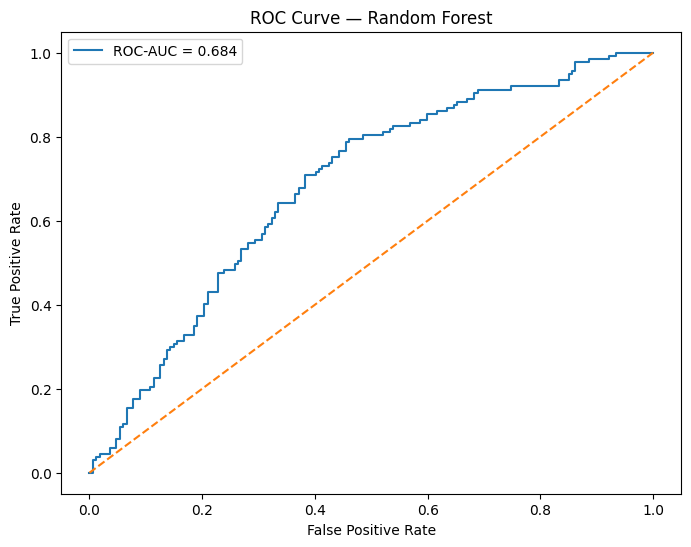

In [11]:

fpr, tpr, _ = roc_curve(y_test, best_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve — {best_name}")
plt.legend()
plt.show()


## Precision-recall curve

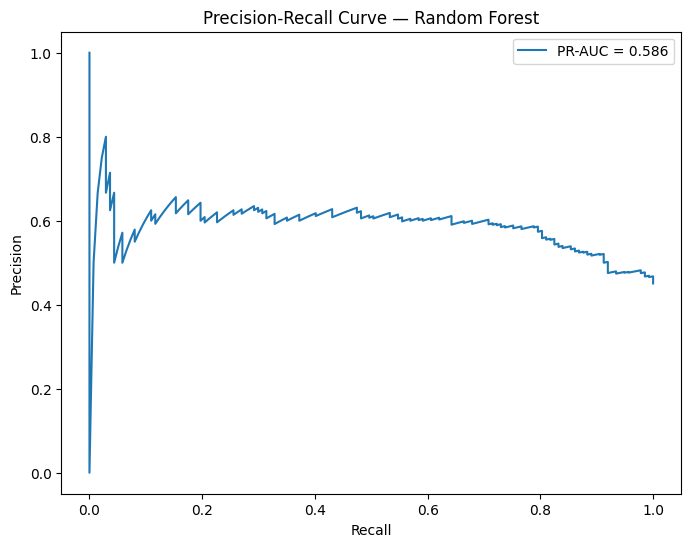

In [12]:

precision, recall, _ = precision_recall_curve(y_test, best_prob)
pr_auc = auc(recall, precision)

plt.figure(figsize=(8,6))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve — {best_name}")
plt.legend()
plt.show()


## Confusion matrix

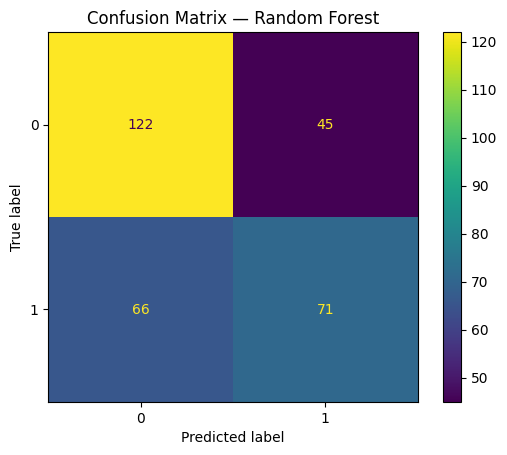

In [13]:

ConfusionMatrixDisplay.from_predictions(y_test, best_pred)
plt.title(f"Confusion Matrix — {best_name}")
plt.show()


## Convert probabilities into business risk

In [14]:

risk_df = test[["CustomerID","monetary","recency","frequency"]].copy()
risk_df["churn_probability"] = best_prob

risk_df["churn_risk"] = pd.cut(
    risk_df["churn_probability"],
    bins=[-0.01, 0.45, 0.75, 1.0],
    labels=["LOW","MEDIUM","HIGH"]
)

display(risk_df.sort_values("churn_probability", ascending=False).head(20))

high_risk = risk_df["churn_risk"].eq("HIGH")
print("High-risk customers:", int(high_risk.sum()))
print("Revenue associated with high-risk customers:",
      round(risk_df.loc[high_risk, "monetary"].sum(), 2))


,CustomerID,monetary,recency,frequency,churn_probability,churn_risk
4928,17892,142.10,65,1,0.844433,HIGH
1299,13826,189.50,86,1,0.837018,HIGH
542,12968,135.95,22,1,0.832465,HIGH
3345,16114,135.75,81,1,0.831715,HIGH
4882,17844,51.56,17,1,0.829409,HIGH
3062,15801,137.22,20,1,0.813691,HIGH
2724,15412,190.53,81,1,0.810772,HIGH
2366,15014,117.73,86,1,0.804603,HIGH
2864,15578,127.10,72,1,0.803370,HIGH
5130,18122,119.19,61,1,0.798889,HIGH


High-risk customers: 28
Revenue associated with high-risk customers: 3359.59


## Optional SHAP explainability

For the final tree-based model, use SHAP to understand which features influence model output.

Interpret SHAP as model explanation, not causal inference.


In [ ]:

# Optional:
#
# import shap
# final_model = models[best_name]
# transformed = final_model.named_steps["prep"].transform(X_test)
# estimator = final_model.named_steps["model"]
# explainer = shap.TreeExplainer(estimator)
# shap_values = explainer.shap_values(transformed)
# shap.summary_plot(shap_values, transformed, feature_names=FEATURES)
